# Chapitre 7 - Cours 2 : isolation faible, read committed et snapshot isolation

Ce notebook couvre le début de la section *Weak Isolation Levels* : *Read Committed*
(*No dirty reads*, *No dirty writes*, *Implementing read committed*) et *Snapshot
Isolation and Repeatable Read* (*Implementing snapshot isolation*,
*Visibility rules for observing a consistent snapshot*, *Indexes and snapshot
isolation*, *Repeatable read and naming confusion*).
Les conflits entre écrivains (mises à jour perdues, write skew, fantômes) sont l'objet du
cours 3.

**Plan.**

1. Pourquoi des niveaux d'isolation « faibles » ? Les bogues de concurrence sont rares.
2. Read committed : pas de lecture sale.
3. Read committed : pas d'écriture sale.
4. Implémenter read committed : verrous d'écriture et deux versions.
5. Lecture biaisée (*read skew*) et instantanés.
6. MVCC : plusieurs versions de chaque ligne.
7. Les règles de visibilité.
8. Index, B-arbres immuables et ramasse-miettes.
9. Snapshot isolation, repeatable read : la confusion des noms.

Tous les scénarios sont rejoués sur le mini-moteur MVCC de
[`ddia/transactions.py`](../../ddia/transactions.py), qui implémente les niveaux
`read_uncommitted`, `read_committed`, `snapshot`, `serializable_ssi`,
`serializable_2pl` (et `none`, sans aucune protection).

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import transactions as tr
from ddia.transactions import R, W, S, run, plot_history, Engine, LEVEL_LABELS
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Pourquoi des niveaux « faibles » ? (section *Weak Isolation Levels*)

Deux transactions qui ne touchent pas les mêmes données, ou qui ne font que lire, peuvent
s'exécuter en parallèle sans risque. Les conditions de course n'apparaissent que si l'une
lit ce que l'autre modifie, ou si les deux modifient la même chose. L'idéal est
l'**isolation sérialisable** : tout se passe comme si les transactions s'exécutaient une
par une. Mais elle a un coût, et beaucoup de bases utilisent par défaut des niveaux plus
faibles, qui protègent contre certaines anomalies seulement.

Le livre insiste sur un point : ces bogues sont **difficiles à trouver par les tests**,
parce qu'ils ne se déclenchent qu'avec un mauvais timing. Quantifions-le. Deux
transactions incrémentent un compteur (lecture, écriture, validation : 3 pas chacune). Il
y a $\binom{6}{3} = 20$ entrelacements possibles ; exécutons-les **tous** à chaque niveau.

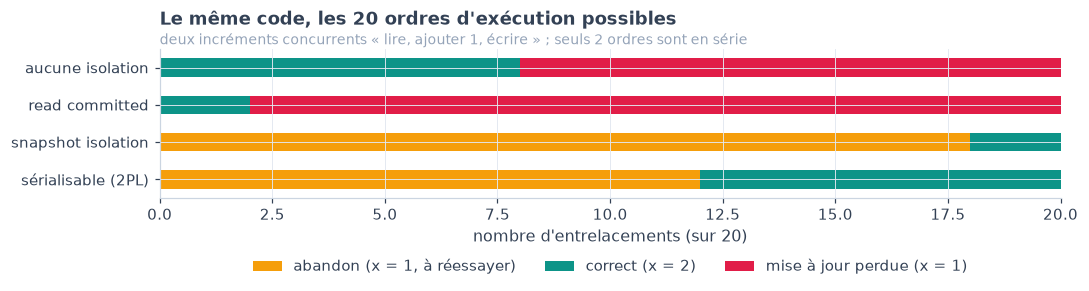

résultat,"abandon (x = 1, à réessayer)",correct (x = 2),mise à jour perdue (x = 1)
niveau,,,
aucune isolation,0,8,12
read committed,0,2,18
snapshot isolation,18,2,0
sérialisable (2PL),12,8,0


In [2]:
def incremente(cle):
    def prog():
        v = yield R(cle)
        yield W(cle, v + 1)
    return prog


def tous_les_entrelacements(n_a, n_b):
    for pos in itertools.combinations(range(n_a + n_b), n_a):
        yield ["A" if i in pos else "B" for i in range(n_a + n_b)]


niveaux = ["none", "read_committed", "snapshot", "serializable_2pl"]
lignes = []
for lvl in niveaux:
    for ordre in tous_les_entrelacements(3, 3):
        r = run({"x": 0}, {"A": incremente("x"), "B": incremente("x")}, ordre, level=lvl)
        lignes.append(dict(niveau=LEVEL_LABELS[lvl], ordre="".join(ordre),
                           résultat="correct (x = 2)" if r.final["x"] == 2 and not r.aborted else
                           ("abandon (x = 1, à réessayer)" if r.aborted else "mise à jour perdue (x = 1)")))
tab = pd.crosstab(pd.DataFrame(lignes)["niveau"], pd.DataFrame(lignes)["résultat"]).reindex(
    [LEVEL_LABELS[l] for l in niveaux])
ax = tab.plot.barh(stacked=True, figsize=(10, 3.6),
                   color={"correct (x = 2)": TEAL, "abandon (x = 1, à réessayer)": AMBER,
                    "mise à jour perdue (x = 1)": ROSE})
ax.invert_yaxis()
ax.set_xlabel("nombre d'entrelacements (sur 20)")
ax.set_ylabel("")
ax.set_title("Le même code, les 20 ordres d'exécution possibles")
subtitle(ax, "deux incréments concurrents « lire, ajouter 1, écrire » ; seuls 2 ordres sont en série")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.6), ncol=3)
plt.tight_layout(); plt.show()
tab

Sans protection, 12 entrelacements sur 20 perdent une mise à jour ; *read committed*
(le niveau par défaut de PostgreSQL, Oracle ou SQL Server) fait même pire, 18 sur 20,
car une transaction ne voit l'écriture de l'autre qu'après sa validation. Ce n'est pas
une anomalie que ce niveau prévient. La snapshot isolation de PostgreSQL et le
verrouillage à deux phases transforment les mauvais entrelacements en **abandons** que
l'application doit réessayer (18 et 12 sur 20) ; les cas restants sont corrects (seuls 2
ordres sont vraiment en série, mais d'autres leur sont équivalents).

Dans une vraie application, les transactions sont courtes et rarement simultanées : la
course ne se produit qu'**occasionnellement**, en production, sous charge, et de façon
presque impossible à reproduire.

Le livre rappelle que ces bogues ont coûté très cher (une plateforme d'échange de Bitcoin
mise en faillite, des données clients corrompues) et qu'un attaquant peut **provoquer**
délibérément la concurrence en envoyant des rafales de requêtes. « Utilisez une base
ACID » ne suffit pas : beaucoup de bases ACID tournent par défaut en isolation faible.

> **À retenir.** Une anomalie qui exige un timing malchanceux passe les tests et frappe
> en production. Il faut connaître précisément ce que chaque niveau d'isolation empêche.

## 2. Read committed : pas de lecture sale (section *No dirty reads*)

*Read committed* fait deux promesses : on ne lit que des données **validées** (pas de
lecture sale), et on n'écrase que des données validées (pas d'écriture sale).

Une **lecture sale** consiste à voir l'écriture d'une transaction qui n'a pas encore
validé. Deux raisons de l'interdire : un lecteur pourrait voir une partie des écritures
d'une transaction et pas le reste (cours 1, la messagerie), et il pourrait voir une donnée
qui sera **annulée**, donc qui n'aura jamais existé. Rejouons ce second cas : un
administrateur passe un prix de 20 € à 25 € puis se ravise (abandon) ; un client lit le
prix entre les deux.

 read uncommitted : le client lit 25 € ; prix final 20 €
   read committed : le client lit 20 € ; prix final 20 €


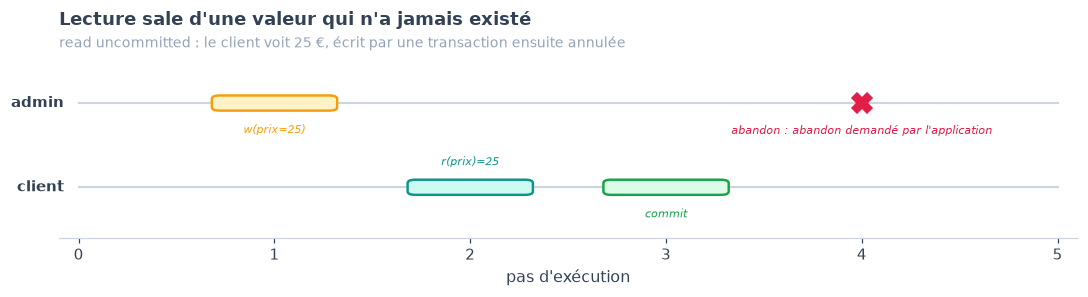

In [3]:
def modif_annulee():
    yield W("prix", 25)
    yield tr.ABORT


def client():
    p = yield R("prix")
    return p


for lvl in ["read_uncommitted", "read_committed"]:
    r = run({"prix": 20}, {"admin": modif_annulee, "client": client},
            ["admin", "client", "client", "admin"], level=lvl)
    print(f"{LEVEL_LABELS[lvl]:>17} : le client lit {r.reads['client'][0]} € ; prix final {r.final['prix']} €")
r = run({"prix": 20}, {"admin": modif_annulee, "client": client},
        ["admin", "client", "client", "admin"], level="read_uncommitted")
plot_history(r, title="Lecture sale d'une valeur qui n'a jamais existé",
             subtitle="read uncommitted : le client voit 25 €, écrit par une transaction ensuite annulée",
             width=10).show()

Sous *read uncommitted*, le client a vu 25 €, un prix qui n'a jamais été validé. Si le
client avait écrit quelque chose à partir de cette lecture, il faudrait aussi l'annuler :
c'est l'**abandon en cascade**. Sous *read committed*, il lit 20 €.

> **À retenir.** Pas de lecture sale = les écritures d'une transaction deviennent visibles
> toutes ensemble, au moment de sa validation, et jamais si elle est annulée.